# T3.7 Multi-Script Router v3 — Unified `router_dataset/` Layout

| Label | Script |
|-------|--------|
| 0 | Devanagari |
| 1 | Tamil |
| 2 | Bengali |
| 3 | Kannada |

**v3 changes (vs v2):**
- Single unified root: `/kaggle/working/router_dataset/`
- All 4 scripts use identical folder-of-subfolders layout (no CSV special-casing)
- `manifest.json` read to validate dataset at startup
- Kannada loaded via `FolderScriptDataset` (same as all other scripts)
- `KannadaMNISTDataset` class removed

**Dataset structure expected:**
```
router_dataset/
  ├── manifest.json
  ├── bengali/      [84 class folders, 5 000 images]
  ├── devanagari/   [46 class folders, 5 000 images]
  ├── kannada/      [10 class folders, 5 000 images]
  └── tamil/        [156 class folders, 5 000 images]
```

## 0. Imports

In [16]:
# ── 0. Imports ───────────────────────────────────────────────
import os, random, json, time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset, Subset
from torchvision import transforms

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(f"PyTorch  : {torch.__version__}")
print(f"CUDA     : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU      : {torch.cuda.get_device_name(0)}")

PyTorch  : 2.10.0+cu128
CUDA     : True
GPU      : Tesla T4


## 1. Config

In [17]:
# ── 1. Config ────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

SCRIPT_NAMES  = ["devanagari", "tamil", "bengali", "kannada"]
SCRIPT_TO_IDX = {s: i for i, s in enumerate(SCRIPT_NAMES)}

IMG_SIZE           = 32
SAMPLES_PER_CLASS  = 500    # images sampled per CHARACTER CLASS
VAL_SPLIT          = 0.15
TEST_SPLIT         = 0.15
BATCH_SIZE         = 128
EPOCHS             = 20
LR                 = 3e-3
DROPOUT            = 0.4
LABEL_SMOOTHING    = 0.1
NUM_WORKERS        = 4

# ── v3: single unified root ──
DATASET_ROOT = Path("/kaggle/input/datasets/kgan31/router-dataset/kaggle/working/router_dataset")
OUTPUT_DIR   = Path("/kaggle/working/models")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SAVE_PATH    = OUTPUT_DIR / "router.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Config ready — DEVICE:", DEVICE)
print("Dataset root:", DATASET_ROOT)

Config ready — DEVICE: cuda
Dataset root: /kaggle/input/datasets/kgan31/router-dataset/kaggle/working/router_dataset


## 2. Validate Dataset via manifest.json

In [18]:
# ── 2. Validate Dataset via manifest.json ────────────────────
manifest_path = DATASET_ROOT / "manifest.json"
if manifest_path.exists():
    with open(manifest_path) as f:
        manifest = json.load(f)
    print("manifest.json found:")
    print(json.dumps(manifest, indent=2))
else:
    print("[WARN] manifest.json not found — proceeding without validation")
    manifest = {}

# Verify each script folder exists
for script in SCRIPT_NAMES:
    p = DATASET_ROOT / script
    status = "✓" if p.exists() else "✗ MISSING"
    n_cls  = len([d for d in p.iterdir() if d.is_dir()]) if p.exists() else 0
    print(f"  [{status}] {script:12s} — {n_cls} class folders")

manifest.json found:
{
  "total_images": 20000,
  "images_per_script": 5000,
  "img_size": 32,
  "scripts": {
    "devanagari": {
      "label_index": 0,
      "path": "/kaggle/working/router_dataset/devanagari",
      "num_classes": 46,
      "num_images": 5000,
      "classes": [
        "character_10_yna",
        "character_11_taamatar",
        "character_12_thaa",
        "character_13_daa",
        "character_14_dhaa",
        "character_15_adna",
        "character_16_tabala",
        "character_17_tha",
        "character_18_da",
        "character_19_dha",
        "character_1_ka",
        "character_20_na",
        "character_21_pa",
        "character_22_pha",
        "character_23_ba",
        "character_24_bha",
        "character_25_ma",
        "character_26_yaw",
        "character_27_ra",
        "character_28_la",
        "character_29_waw",
        "character_2_kha",
        "character_30_motosaw",
        "character_31_petchiryakha",
        "character_32_patalosaw

## 3. Dataset Classes

In [19]:
# ── 3. Dataset Classes ───────────────────────────────────────
IMAGE_EXTS = {".png"}

def collect_paths_balanced(data_dir: Path, samples_per_class: int) -> list:
    """
    Walk ONE level of subfolders (each = one character class).
    Sample up to `samples_per_class` images per class.
    Returns a flat list of file paths covering ALL classes.
    """
    all_paths = []
    class_dirs = sorted([d for d in data_dir.iterdir() if d.is_dir()])
    if not class_dirs:
        raise FileNotFoundError(f"No class sub-folders found in {data_dir}")
    for cls_dir in class_dirs:
        imgs = [
            str(e.path)
            for e in os.scandir(cls_dir)
            if e.is_file() and Path(e.name).suffix.lower() in IMAGE_EXTS
        ]
        if not imgs:
            continue
        random.shuffle(imgs)
        all_paths.extend(imgs[:samples_per_class])
    return all_paths


class FolderScriptDataset(Dataset):
    """
    Folder-of-subfolders layout with per-class balanced sampling.
    Used for ALL four scripts in v3.
    """

    def __init__(self, paths: list, script_label: int, transform=None):
        self.paths        = paths
        self.script_label = script_label
        self.transform    = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("L")
        if self.transform:
            img = self.transform(img)
        return img, self.script_label


print("Dataset classes defined.")

Dataset classes defined.


## 4. Transforms

In [20]:
# ── 4. Transforms ────────────────────────────────────────────
def get_transforms(split: str):
    """split: 'train' | 'val' | 'test'"""
    if split == "train":
        return transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomRotation(10),
            transforms.RandomAffine(0, translate=(0.1, 0.1)),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5]),
        ])
    return transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5]),
    ])


print("Transforms defined.")

Transforms defined.


## 5. Build Datasets (train / val / test)

In [21]:
# ── 5. Build Datasets (train / val / test) ───────────────────
def make_splits(paths: list, script_label: int, n: int):
    """
    Given a flat list of image paths and their script label,
    return (train_subset, val_subset, test_subset) with correct transforms.
    """
    n_test = int(n * TEST_SPLIT)
    n_val  = int(n * VAL_SPLIT)
    idx    = list(range(n))
    random.shuffle(idx)

    test_idx  = idx[:n_test]
    val_idx   = idx[n_test: n_test + n_val]
    train_idx = idx[n_test + n_val:]

    tr = FolderScriptDataset(paths, script_label, transform=get_transforms("train"))
    vl = FolderScriptDataset(paths, script_label, transform=get_transforms("val"))
    te = FolderScriptDataset(paths, script_label, transform=get_transforms("test"))

    return Subset(tr, train_idx), Subset(vl, val_idx), Subset(te, test_idx)


train_sets, val_sets, test_sets = [], [], []
active_scripts = []
counts = {}
t0 = time.time()

for script in SCRIPT_NAMES:
    script_dir = DATASET_ROOT / script
    if not script_dir.exists():
        print(f"[SKIP] {script} — folder not found at {script_dir}")
        continue

    try:
        paths = collect_paths_balanced(script_dir, SAMPLES_PER_CLASS)
    except FileNotFoundError as e:
        print(f"[SKIP] {script} — {e}")
        continue

    n     = len(paths)
    label = SCRIPT_TO_IDX[script]
    n_cls = len([d for d in script_dir.iterdir() if d.is_dir()])
    counts[script] = n
    active_scripts.append(script)
    print(f"[{script:12s}] {n:>6} images across {n_cls} classes "
          f"(~{n // n_cls} per class)")

    tr, vl, te = make_splits(paths, label, n)
    train_sets.append(tr)
    val_sets.append(vl)
    test_sets.append(te)

assert train_sets, "No datasets loaded! Check DATASET_ROOT and folder structure."
print(f"\nData collected in {time.time()-t0:.1f}s")

train_dataset = ConcatDataset(train_sets)
val_dataset   = ConcatDataset(val_sets)
test_dataset  = ConcatDataset(test_sets)

_dl_kw = dict(num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,    shuffle=True,  **_dl_kw)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE * 2, shuffle=False, **_dl_kw)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE * 2, shuffle=False, **_dl_kw)

print(f"Train: {len(train_dataset):,}  |  Val: {len(val_dataset):,}  |  Test: {len(test_dataset):,}")
print(f"Active scripts: {active_scripts}")

[devanagari  ]   5000 images across 46 classes (~108 per class)
[tamil       ]   5000 images across 156 classes (~32 per class)
[bengali     ]   5000 images across 84 classes (~59 per class)
[kannada     ]   5000 images across 10 classes (~500 per class)

Data collected in 12.4s
Train: 14,000  |  Val: 3,000  |  Test: 3,000
Active scripts: ['devanagari', 'tamil', 'bengali', 'kannada']


## 6. Visualise Sample Images

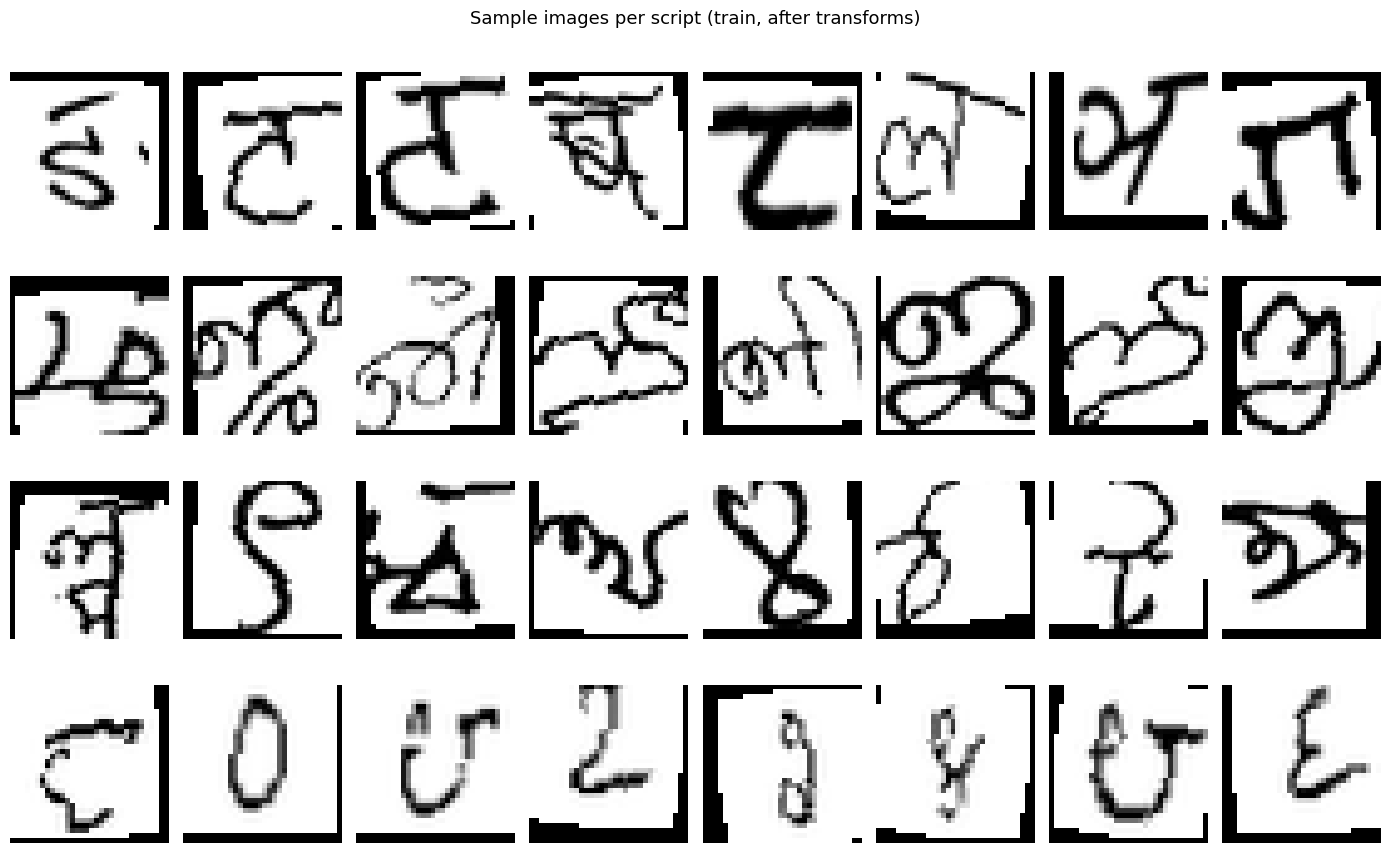

In [22]:
# ── 6. Visualise Sample Images ───────────────────────────────
fig, axes = plt.subplots(
    len(active_scripts), 8,
    figsize=(14, 2 * len(active_scripts) + 1)
)
if len(active_scripts) == 1:
    axes = [axes]   # make iterable

fig.suptitle("Sample images per script (train, after transforms)", fontsize=13)

for row, (script, ds) in enumerate(zip(active_scripts, train_sets)):
    imgs, _ = next(iter(DataLoader(ds, batch_size=8, shuffle=True)))
    for col in range(8):
        ax = axes[row][col]
        ax.imshow((imgs[col].squeeze().numpy() * 0.5 + 0.5), cmap="gray")
        ax.axis("off")
        if col == 0:
            ax.set_ylabel(script, fontsize=9, rotation=0, labelpad=55, va="center")

plt.tight_layout()
plt.savefig("/kaggle/working/sample_images.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Router CNN

In [23]:
# ── 7. Router CNN ─────────────────────────────────────────────
class RouterCNN(nn.Module):
    def __init__(self, num_classes: int = 4, dropout: float = 0.4):
        super().__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(True),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(True),
            nn.MaxPool2d(2), nn.Dropout2d(0.1),           # 32 → 16
            # Block 2
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.MaxPool2d(2), nn.Dropout2d(0.2),           # 16 → 8
            # Block 3
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.MaxPool2d(2),                              # 8  → 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256), nn.ReLU(True), nn.Dropout(dropout),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

    @torch.no_grad()
    def predict_proba(self, x):
        return torch.softmax(self(x), dim=1)


num_classes = len(active_scripts)
model       = RouterCNN(num_classes=num_classes, dropout=DROPOUT).to(DEVICE)
n_param     = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"RouterCNN ready  |  classes: {num_classes}  |  params: {n_param:,}")

RouterCNN ready  |  classes: 4  |  params: 665,060


## 8. Loss / Optimiser / Scheduler

In [24]:
# ── 8. Loss / Optimiser / Scheduler ─────────────────────────
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR,
    steps_per_epoch=len(train_loader),
    epochs=EPOCHS,
    pct_start=0.3,
)

## 9. Training Loop

In [25]:
# ── 9. Training Loop ────────────────────────────────────────
def train_one_epoch(model, loader, criterion, optimizer, scheduler):
    model.train()
    loss_sum = correct = total = 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        logits = model(imgs)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        scheduler.step()
        loss_sum += loss.item() * imgs.size(0)
        correct  += (logits.argmax(1) == labels).sum().item()
        total    += imgs.size(0)
    return loss_sum / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum = correct = total = 0
    all_preds, all_labels = [], []
    for imgs, labels in loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        logits = model(imgs)
        loss   = criterion(logits, labels)
        preds  = logits.argmax(1)
        loss_sum += loss.item() * imgs.size(0)
        correct  += (preds == labels).sum().item()
        total    += imgs.size(0)
        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
    return loss_sum / total, correct / total, all_preds, all_labels


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0

print(f"{'Epoch':>6}  {'TrainLoss':>10}  {'TrainAcc':>9}  {'ValLoss':>8}  {'ValAcc':>7}")
print("─" * 56)

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc          = train_one_epoch(model, train_loader, criterion, optimizer, scheduler)
    vl_loss, vl_acc, _, _   = evaluate(model, val_loader, criterion)
    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(vl_loss)
    history["val_acc"].append(vl_acc)
    flag = ""
    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        torch.save({
            "epoch"           : epoch,
            "model_state_dict": model.state_dict(),
            "val_acc"         : vl_acc,
            "script_names"    : active_scripts,
            "script_to_idx"   : {s: SCRIPT_TO_IDX[s] for s in active_scripts},
            "img_size"        : IMG_SIZE,
            "num_classes"     : num_classes,
        }, SAVE_PATH)
        flag = "  ✓ saved"
    print(f"{epoch:>6}  {tr_loss:>10.4f}  {tr_acc:>8.2%}  {vl_loss:>8.4f}  {vl_acc:>6.2%}{flag}")

print(f"\nBest val accuracy: {best_val_acc:.2%}  →  {SAVE_PATH}")

 Epoch   TrainLoss   TrainAcc   ValLoss   ValAcc
────────────────────────────────────────────────────────
     1      0.9071    68.94%    0.8349  73.13%  ✓ saved
     2      0.6686    83.84%    0.6364  84.90%  ✓ saved
     3      0.6069    87.76%    0.5711  89.40%  ✓ saved
     4      0.5655    90.67%    0.5529  91.30%  ✓ saved
     5      0.5235    92.95%    0.5135  93.10%  ✓ saved
     6      0.5027    94.46%    0.4473  97.53%  ✓ saved
     7      0.4855    95.01%    0.4154  98.23%  ✓ saved
     8      0.4660    96.34%    0.4004  98.67%  ✓ saved
     9      0.4514    97.00%    0.4217  97.33%
    10      0.4397    97.44%    0.3915  99.03%  ✓ saved
    11      0.4302    97.94%    0.4308  96.63%
    12      0.4230    98.12%    0.3999  98.60%
    13      0.4183    98.29%    0.3998  98.33%
    14      0.4102    98.70%    0.3805  99.27%  ✓ saved
    15      0.4070    98.75%    0.3817  99.00%
    16      0.4040    98.92%    0.3803  99.20%
    17      0.3989    99.17%    0.3778  99.23%
    1

## 10. Training Curves

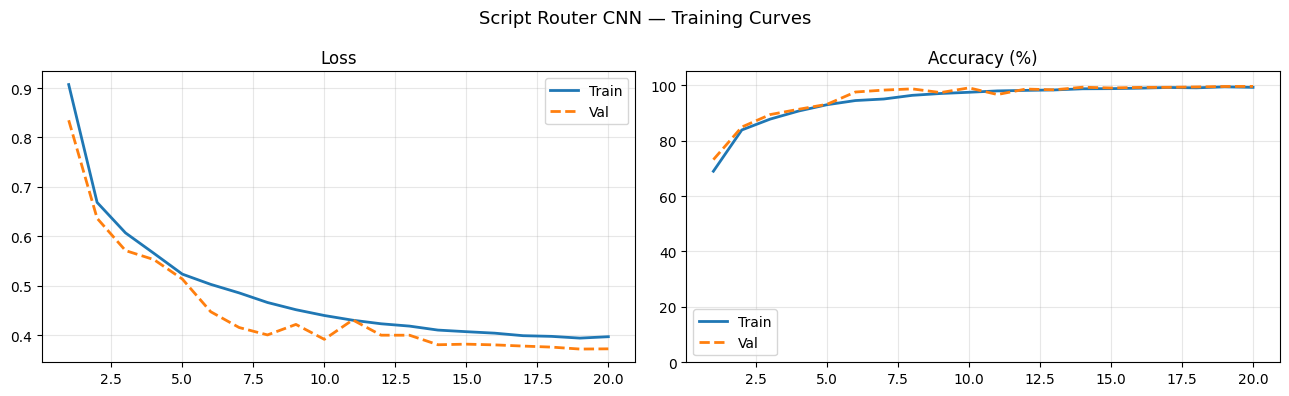

In [26]:
# ── 10. Training Curves ──────────────────────────────────────
er = range(1, EPOCHS + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
ax1.plot(er, history["train_loss"], label="Train", lw=2)
ax1.plot(er, history["val_loss"],   label="Val",   lw=2, ls="--")
ax1.set_title("Loss"); ax1.legend(); ax1.grid(alpha=0.3)
ax2.plot(er, [a * 100 for a in history["train_acc"]], label="Train", lw=2)
ax2.plot(er, [a * 100 for a in history["val_acc"]],   label="Val",   lw=2, ls="--")
ax2.set_title("Accuracy (%)"); ax2.legend(); ax2.grid(alpha=0.3); ax2.set_ylim([0, 105])
plt.suptitle("Script Router CNN — Training Curves", fontsize=13)
plt.tight_layout()
plt.savefig("/kaggle/working/training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

## 11. Val Classification Report & Confusion Matrix

=== VALIDATION SET ===
              precision    recall  f1-score   support

  devanagari       1.00      1.00      1.00       750
       tamil       1.00      0.99      0.99       750
     bengali       0.99      1.00      0.99       750
     kannada       1.00      1.00      1.00       750

    accuracy                           1.00      3000
   macro avg       1.00      1.00      1.00      3000
weighted avg       1.00      1.00      1.00      3000



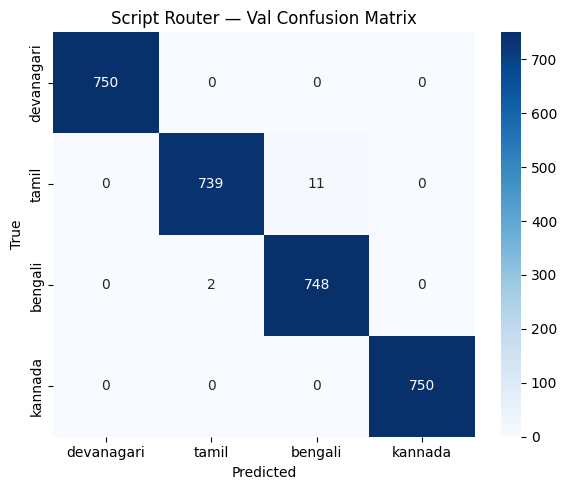

In [27]:
# ── 11. Val Classification Report & Confusion Matrix ────────
ckpt = torch.load(SAVE_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["model_state_dict"])

_, _, vl_preds, vl_labels = evaluate(model, val_loader, criterion)
active_label_ids = [SCRIPT_TO_IDX[s] for s in active_scripts]

print("=== VALIDATION SET ===")
print(classification_report(
    vl_labels, vl_preds,
    labels=active_label_ids,
    target_names=active_scripts
))

cm = confusion_matrix(vl_labels, vl_preds, labels=active_label_ids)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=active_scripts, yticklabels=active_scripts, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title("Script Router — Val Confusion Matrix")
plt.tight_layout()
plt.savefig("/kaggle/working/val_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## 12. TEST SET Evaluation (held-out)


FINAL TEST SET EVALUATION  (never seen during training)

Overall Test Accuracy : 99.03%

              precision    recall  f1-score   support

  devanagari       1.00      1.00      1.00       750
       tamil       1.00      0.97      0.98       750
     bengali       0.97      1.00      0.98       750
     kannada       1.00      1.00      1.00       750

    accuracy                           0.99      3000
   macro avg       0.99      0.99      0.99      3000
weighted avg       0.99      0.99      0.99      3000



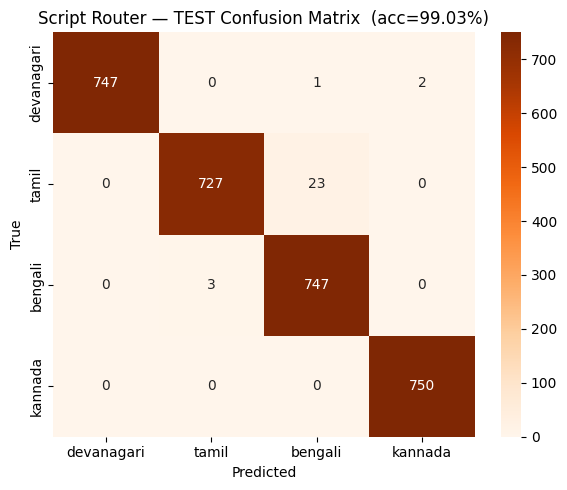

In [28]:
# ── 12. TEST SET Evaluation (held-out) ───────────────────────
print("\n" + "=" * 50)
print("FINAL TEST SET EVALUATION  (never seen during training)")
print("=" * 50)

_, test_acc, te_preds, te_labels = evaluate(model, test_loader, criterion)
print(f"\nOverall Test Accuracy : {test_acc:.2%}\n")
print(classification_report(
    te_labels, te_preds,
    labels=active_label_ids,
    target_names=active_scripts
))

cm_test = confusion_matrix(te_labels, te_preds, labels=active_label_ids)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Oranges",
            xticklabels=active_scripts, yticklabels=active_scripts, ax=ax)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Script Router — TEST Confusion Matrix  (acc={test_acc:.2%})")
plt.tight_layout()
plt.savefig("/kaggle/working/test_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

## 13. Inference Helper

In [29]:
# ── 13. Inference Helper ────────────────────────────────────
def load_router(checkpoint_path: str, device: str = "cpu") -> RouterCNN:
    ckpt = torch.load(checkpoint_path, map_location=device)
    m    = RouterCNN(num_classes=ckpt["num_classes"])
    m.load_state_dict(ckpt["model_state_dict"])
    m.eval()
    return m, ckpt["script_names"]


def predict_script(
    model: RouterCNN,
    pil_image: Image.Image,
    script_names: list,
    device: str = "cpu",
) -> dict:
    tf     = get_transforms("test")
    tensor = tf(pil_image.convert("L")).unsqueeze(0).to(device)
    probs  = model.predict_proba(tensor).squeeze(0).tolist()
    top    = int(np.argmax(probs))
    return {
        "script"       : script_names[top],
        "index"        : top,
        "confidence"   : probs[top],
        "probabilities": dict(zip(script_names, probs)),
    }


# ── Quick smoke-test on one test image ──
sample_imgs, sample_labels = next(iter(test_loader))
model.eval()
with torch.no_grad():
    sample_probs = model.predict_proba(sample_imgs[:4].to(DEVICE)).cpu()

print("Smoke-test — first 4 test images:")
for i in range(4):
    pred_idx  = sample_probs[i].argmax().item()
    true_idx  = sample_labels[i].item()
    conf      = sample_probs[i][pred_idx].item()
    print(f"  True: {active_scripts[active_label_ids.index(true_idx)]:12s}  "
          f"Pred: {active_scripts[pred_idx]:12s}  "
          f"Conf: {conf:.2%}")

Smoke-test — first 4 test images:
  True: devanagari    Pred: devanagari    Conf: 91.44%
  True: devanagari    Pred: devanagari    Conf: 92.69%
  True: devanagari    Pred: devanagari    Conf: 94.20%
  True: devanagari    Pred: devanagari    Conf: 87.49%


## 14. Save History & File Summary

In [30]:
# ── 14. Save History & File Summary ─────────────────────────
history_path = Path("/kaggle/working/router_history.json")
with open(history_path, "w") as f:
    json.dump({
        "config": {
            "img_size"         : IMG_SIZE,
            "samples_per_class": SAMPLES_PER_CLASS,
            "epochs"           : EPOCHS,
            "batch_size"       : BATCH_SIZE,
            "lr"               : LR,
            "active_scripts"   : active_scripts,
        },
        "best_val_acc": best_val_acc,
        "test_acc"    : test_acc,
        "history"     : history,
    }, f, indent=2)

print("\nAll outputs saved to /kaggle/working/")
for p in sorted(Path("/kaggle/working").rglob("*")):
    if p.is_file() and not str(p).startswith("/kaggle/working/router_dataset"):
        print(f"  {str(p.relative_to('/kaggle/working')):50s}  {p.stat().st_size/1024:7.1f} KB")


All outputs saved to /kaggle/working/
  .virtual_documents/__notebook_source__.ipynb           18.0 KB
  models/router.pth                                    2611.7 KB
  router_history.json                                     2.3 KB
  sample_images.png                                      72.0 KB
  test_confusion_matrix.png                              38.2 KB
  training_curves.png                                    60.6 KB
  val_confusion_matrix.png                               36.2 KB


In [31]:
torch.save({
    "model_state_dict": model.state_dict(),
    "script_names"    : active_scripts,
    "script_to_idx"   : {s: SCRIPT_TO_IDX[s] for s in active_scripts},
    "img_size"        : IMG_SIZE,
    "num_classes"     : len(active_scripts),
}, "/kaggle/working/models/router.pt")